# Lab 8 — Morphological Image Processing


---
## Theory — What is morphological processing?

**Morpholgical Processing** is modifying and improving the shapes in an image.

 The two ingredients of every morphological operation:

1. **The image** — a binary image where white (`255`) pixels are *foreground* (the object) and black (`0`) pixels are *background*.
2. **The structuring element** (also called *kernel* or *probe*) — a small shape (e.g., 3×3 square, 5×5 circle) that you slide across the image.

### The four basic operations
<img src="https://drive.google.com/thumbnail?id=129tujHkYNk3b8US7HEqbt-WymOZgwMnA&sz=w1000" width="600">



| Operation | What it does | Formula | Effect on objects |
|---|---|---|---|
| **Erosion** | Shrinks objects | $A \ominus B$ | Removes thin parts and noise |
| **Dilation** | Grows objects | $A \oplus B$ | Fills gaps, thickens objects |
| **Opening** | Erosion then dilation | $A \circ B = (A \ominus B) \oplus B$ | Removes small noise but keeps overall size |
| **Closing** | Dilation then erosion | $A \bullet B = (A \oplus B) \ominus B$ | Fills small holes but keeps overall size |

### How to remember each one

- **Erosion eats away** at object edges → output is smaller.
- **Dilation expands** object edges → output is larger.
- **Opening = "open up" the gaps** between separated noise specks (removes noise without shrinking real objects).
- **Closing = "close up" small holes** inside objects (fills gaps without growing real objects).



---
## Task 1 — Create a Binary Image with Shapes and Noise

The lab provides this code to generate a synthetic test image with **4 shapes** and some random **salt noise**:
- A solid filled circle on the left
- A solid filled rectangle
- A hollow (outline-only) circle
- A hollow rectangle
- Plus 1000 random scattered white pixels (noise)

## Setup — Import libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

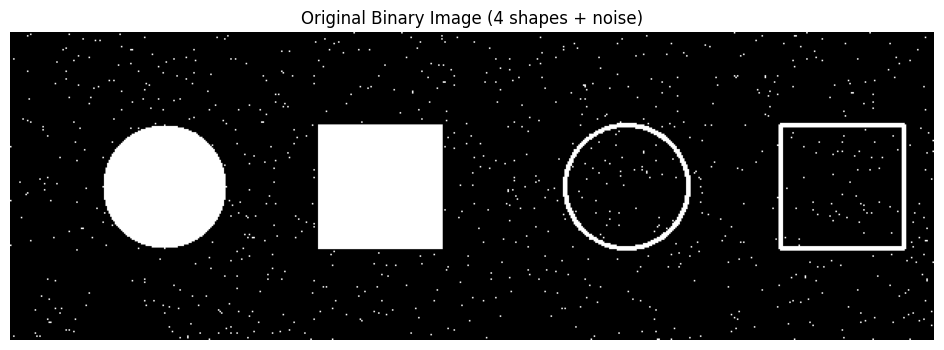

In [2]:
# Create a binary image with shapes and noise
image = np.zeros((200, 600), dtype=np.uint8)
cv2.circle(image, (100, 100), 40, 255, -1)              # Solid circle (filled) - radius=40
cv2.rectangle(image, (200, 60), (280, 140), 255, -1)    # Solid rectangle (filled) - start & end points= (200, 60), (280, 140)
cv2.circle(image, (400, 100), 40, 255, 2)               # Hollow circle (outline)
cv2.rectangle(image, (500, 60), (580, 140), 255, 2)     # Hollow rectangle (outline)

# Add small noise (1000 random white pixels)
np.random.seed(0)
for _ in range(1000):
    x, y = np.random.randint(0, 600), np.random.randint(0, 200)
    image[y, x] = 255

plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

---
Define the Structuring Element (5×5 Square Kernel)

The structuring element is the "shape" we slide across the image. The simplest one is a **square of all ones**:

$$K = \begin{bmatrix} 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \end{bmatrix}$$

**Why a square?** It's directionally neutral (same effect horizontally and vertically) and fast to compute. The `1`s indicate which positions in the neighborhood are "active" — for a square kernel, every neighbor counts.

In [3]:
kernel = np.ones((5, 5), np.uint8)
print("Square kernel (5×5):")
print(kernel)

Square kernel (5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


---
## Assessment Task 1 — Apply Erosion, Dilation, Opening, Closing (Square Kernel)

For each operation we use a single OpenCV function:

| Operation | OpenCV call |
|---|---|
| Erosion | `cv2.erode(image, kernel, iterations=1)` |
| Dilation | `cv2.dilate(image, kernel, iterations=1)` |
| Opening | `cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)` |
| Closing | `cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)` |



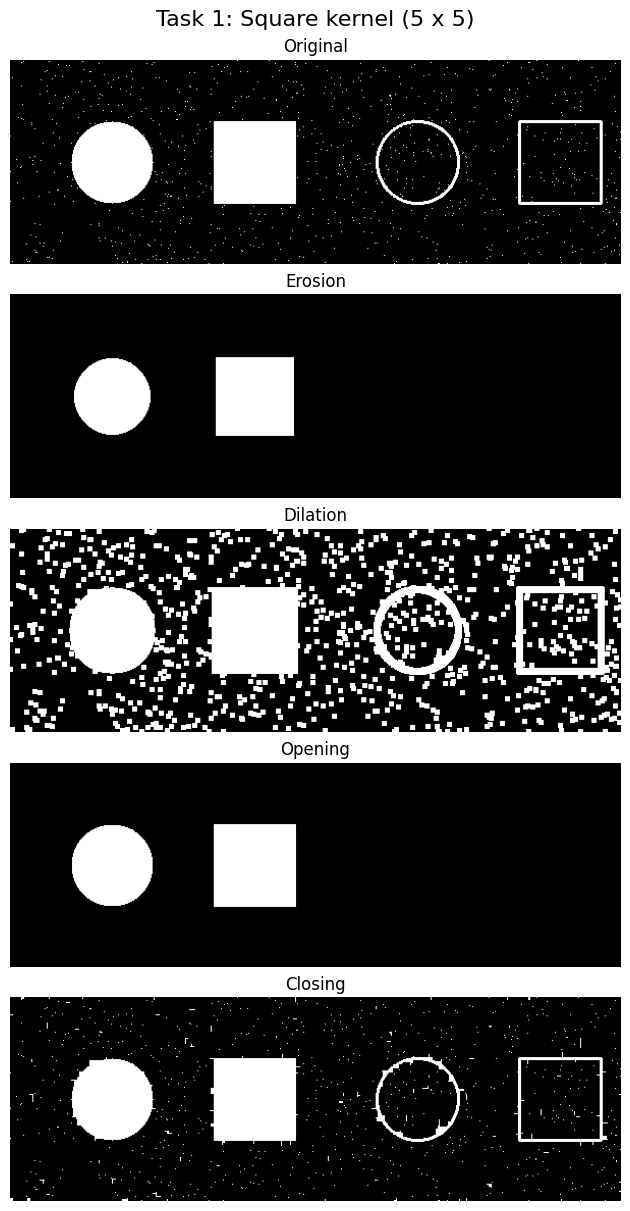

In [4]:
# Apply each operation independently to the original noisy image.
eroded_square = cv2.erode(image, kernel, iterations=1)
dilated_square = cv2.dilate(image, kernel, iterations=1)
opened_square = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)
closed_square = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

# Show the original image and all four results.
square_results = [image, eroded_square, dilated_square,
                  opened_square, closed_square]
titles = ['Original', 'Erosion', 'Dilation', 'Opening', 'Closing']

fig, axes = plt.subplots(5, 1, figsize=(12, 12), constrained_layout=True)
for ax, result, title in zip(axes, square_results, titles):
    ax.imshow(result, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
fig.suptitle('Task 1: Square kernel (5 x 5)', fontsize=16)
plt.show()

## Assessment Task 2 — Repeat with a Circular Kernel

Apply erosion, dilation opening and closing to the generated image in Task#1 using the following structuring element:

In [5]:
def circular_structuring_element(radius):
    """Creates a binary circular structuring element (exact circle)"""
    size = 2 * radius + 1                    # Ensure kernel size is odd
    kernel = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)  # Draw filled circle
    return kernel

# Define radius
radius = 5
circle_kernel = circular_structuring_element(radius)

Circular kernel (radius=5, size=(11, 11)):
[[0 0 0 0 0 1 0 0 0 0 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [1 1 1 1 1 1 1 1 1 1 1]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 1 0 0 0 0 0]]


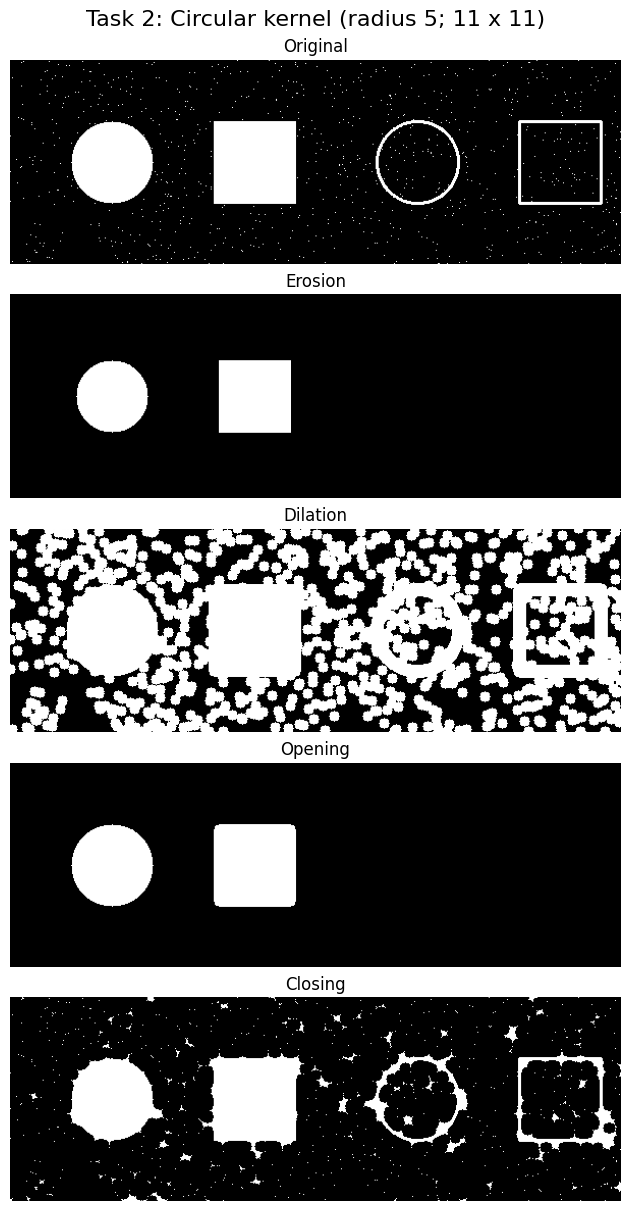

In [6]:
print(f'Circular kernel (radius={radius}, size={circle_kernel.shape}):')
print(circle_kernel)

# Repeat the four operations on the same original image.
eroded_circle = cv2.erode(image, circle_kernel, iterations=1)
dilated_circle = cv2.dilate(image, circle_kernel, iterations=1)
opened_circle = cv2.morphologyEx(image, cv2.MORPH_OPEN, circle_kernel)
closed_circle = cv2.morphologyEx(image, cv2.MORPH_CLOSE, circle_kernel)

circle_results = [image, eroded_circle, dilated_circle,
                  opened_circle, closed_circle]
fig, axes = plt.subplots(5, 1, figsize=(12, 12), constrained_layout=True)
for ax, result, title in zip(axes, circle_results, titles):
    ax.imshow(result, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
fig.suptitle('Task 2: Circular kernel (radius 5; 11 x 11)', fontsize=16)
plt.show()

## Assessment Task 3 — Difference Between Square vs Circular Kernel

 In your own words, explain the difference between the results in Task#1 and Task#2



### Answer

Both kernels shrink white objects during erosion, grow them during dilation,
remove isolated white noise during opening, and connect nearby white regions
or close small black gaps during closing. However, their sizes and shapes
produce different results:

| Operation | Square kernel (5 x 5) | Circular kernel (radius 5; 11 x 11) |
|---|---|---|
| **Erosion** | Shrinks the filled shapes and removes isolated white noise. The thin hollow outlines disappear. | Shrinks the filled shapes more because the kernel is larger. The thin hollow outlines also disappear. |
| **Dilation** | Enlarges the shapes and noise specks. Expansion has a more square appearance, especially around isolated pixels and rectangle corners. | Enlarges the shapes and noise specks more. Expansion around isolated pixels and rectangle corners looks rounder; more nearby regions join together. |
| **Opening** | Removes the scattered salt noise and largely preserves the filled shapes. The thin hollow outlines are removed. | Also removes salt noise and the thin outlines. It rounds the filled rectangle's corners more, while largely preserving the filled circle. |
| **Closing** | Connects nearby white pixels and fills small gaps. It does not remove salt noise, and the large hollow interiors remain. | Connects more nearby regions and fills larger small gaps because of the larger kernel. Noise joins into more visible clusters. The large hollow interiors still remain. |

**Why the hollow outlines disappear:** They are thinner than either kernel,
so erosion removes them. Opening starts with erosion; the later dilation
cannot restore outlines that have disappeared completely.

**Size versus shape:** The circular kernel has radius 5, so its dimensions are
`2 * 5 + 1 = 11` by `11`. The stronger changes cannot be attributed only to
its circular shape, because it is also larger than the 5 x 5 square. A fair
comparison of shape alone would use kernels with the same bounding size.